# Classical Segmentation in Materials Microscopy
### Thresholding and Watershed Demo

**Scenario.** We analyse two topographic (AFM) scans of semiconductor surfaces, one with surface defect pits and one with quantum dots:

| Case | Dataset | Features | Polarity | Core lesson |
|---|---|---|---|---|
| 1 | GaN dislocation pits (`pits.spm`, 3 µm × 3 µm) | **dark pits** (depressions) | `img < t` | Global thresholding works when background is relatively flat |
| 2 | GaAs quantum dots (`dots.spm`, 1 × 1 µm) | **bright dots** (elevations) | `img > t` | Global thresholds fail on non-uniform backgrounds, local thresholding corrects background variation |
| 3 | GaN pit scan again | dark pits | `img < t` | Marker-controlled watershed **splits fused instances** |

**Workflow:** load raw Bruker `.spm` → pySPM levelling (row alignment + plane subtraction) → threshold → distance transform + markers → watershed.

### One-time setup on a bare machine
Note: Python 3.10 or 3.11 recommended for this demo

In [53]:
%pip install --quiet pyspm scikit-image matplotlib scipy numpy ipywidgets

Note: you may need to restart the kernel to use updated packages.


> ⚠️ **If this is your first run:** after the `pip install` above, **restart the kernel**
> (Kernel → Restart Kernel…) so the freshly installed packages are picked up, then
> re-run all cells from the top. You only need to do this once per environment.


### Import Python libraries and create preprocessing function for Bruker AFM data

In [54]:
# ── Imports & shared helpers ────────────────────────────────────────────────
%matplotlib inline
import copy

import numpy as np
import matplotlib.pyplot as plt

import pySPM                                    # Bruker .spm AFM reader
from scipy import ndimage as ndi
from scipy.ndimage import distance_transform_edt
from skimage import filters, morphology, segmentation
from skimage.feature import peak_local_max

import ipywidgets as widgets
from IPython.display import display

plt.rcParams.update({
    'figure.dpi': 100,
    'font.size': 11,
    'axes.titlesize': 11,
    'figure.facecolor': 'white',
})


def level_bruker_scan(file_path):
    """Read a Bruker .spm scan and apply pySPM's native levelling pipeline.

    Returns
    -------
    (raw_pixels, corrected_pixels)
        Raw and corrected height maps in nm, each of shape (N, N).
    """
    scan = pySPM.Bruker(file_path)
    raw = copy.deepcopy(scan.get_channel("Height Sensor")).pixels

    topo = copy.deepcopy(scan.get_channel("Height Sensor"))
    topo.correct_median_diff()                      # align scan rows
    corrected = topo.corr_fit2d(inline=False).pixels  # 2-D plane levelling
    return raw, corrected

## Case 1 — Global thresholding on GaN dislocation pits

**Feature polarity: pits are *dark* (below the surface plane), so a pit pixel satisfies `height < t`.**

AFM raw height data is **never** ready for segmentation as recorded:

| artefact | cause | fix |
|---|---|---|
| row offsets (streaks along the fast-scan direction) | piezo drift / thermal noise between scan lines | `correct_median_diff()` |
| sample tilt + scanner bow (slow quadratic curvature) | physical tilt of the sample mount | `corr_fit2d()` |

`pySPM` ships a correction pipeline tailored to Bruker files, so we do **not** roll our own baseline here. The two calls below are the canonical Bruker recipe:

1. `topo.correct_median_diff()` — aligns scan rows so the median difference between neighbouring rows is zero.
2. `topo.corr_fit2d(inline=False)` — fits and subtracts a 2-D plane to remove sample tilt.

Only **after** levelling is a threshold a meaningful description of "lower than the surface". The cell below loads the scan, applies both corrections and prints the physical scale so every axis in the demo carries real units.

In [55]:
GAN_PATH    = 'afm_scan.spm'
GAN_SCAN_UM = 3.0                                                           # physical field of view
gan_raw, gan_height = level_bruker_scan(GAN_PATH)

GAN_N = gan_height.shape[0]                                                 # hieght in pixels
GAN_NM_PER_PX = GAN_SCAN_UM * 1000 / GAN_N                                  # nm per pixel
GAN_EXTENT_NM = [0, GAN_N * GAN_NM_PER_PX, GAN_N * GAN_NM_PER_PX, 0]        # extent of image for plotting

print(f'GaN scan: {GAN_N}×{GAN_N} px ({GAN_SCAN_UM} × {GAN_SCAN_UM} µm)')

GaN scan: 512×512 px (3.0 × 3.0 µm)


Both corrections leave the pits untouched but pull the background onto a flat 0 nm plane. The raw scan on the left carries the tilt and the row streaks; the corrected scan on the right is what the thresholding sections will consume.

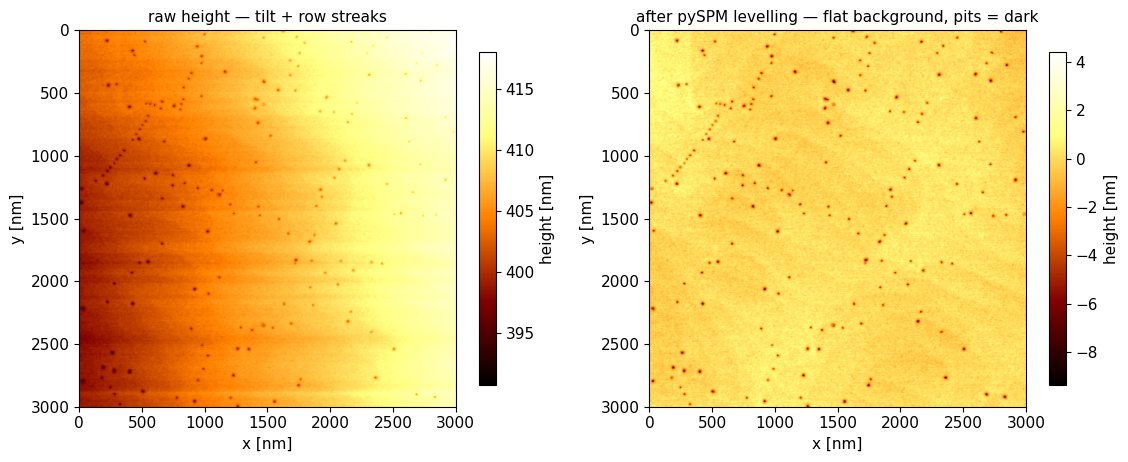

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))

im0 = axes[0].imshow(gan_raw, cmap='afmhot', extent=GAN_EXTENT_NM)
axes[0].set_title('raw height — tilt + row streaks')
axes[0].set_xlabel('x [nm]')
axes[0].set_ylabel('y [nm]')
plt.colorbar(im0, ax=axes[0], shrink=0.85, label='height [nm]')

im1 = axes[1].imshow(gan_height, cmap='afmhot', extent=GAN_EXTENT_NM)
axes[1].set_title('after pySPM levelling — flat background, pits = dark')
axes[1].set_xlabel('x [nm]')
axes[1].set_ylabel('y [nm]')
plt.colorbar(im1, ax=axes[1], shrink=0.85, label='height [nm]')

plt.tight_layout()
plt.show()

After levelling, the GaN background sits in a narrow band around 0 nm and the dislocation pits form a clearly separated **negative tail** in the histogram. When feature and background populations are this well separated, a **single global cutoff** — Otsu's automatic choice, or a hand-picked nm value — segments nearly every isolated pit. This is the "easy" case, and it is worth internalizing *when* it works.

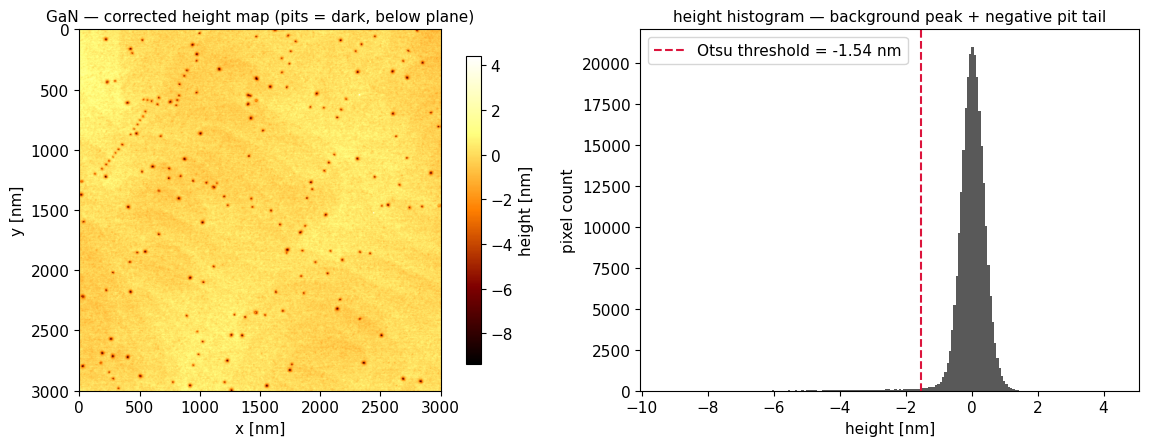

Otsu global threshold for pits: -1.540 nm (1.1% of pixels)


In [57]:
GAN_OTSU = filters.threshold_otsu(gan_height)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

im = axes[0].imshow(gan_height, cmap='afmhot', extent=GAN_EXTENT_NM)
axes[0].set_title('GaN — corrected height map (pits = dark, below plane)')
axes[0].set_xlabel('x [nm]')
axes[0].set_ylabel('y [nm]')
plt.colorbar(im, ax=axes[0], shrink=0.85, label='height [nm]')

axes[1].hist(gan_height.ravel(), bins=200, color='0.35')
axes[1].axvline(GAN_OTSU, color='crimson', ls='--', lw=1.5,
                label=f'Otsu threshold = {GAN_OTSU:+.2f} nm')
axes[1].set_title('height histogram — background peak + negative pit tail')
axes[1].set_xlabel('height [nm]')
axes[1].set_ylabel('pixel count')
axes[1].legend()

plt.tight_layout()
plt.show()

print(f'Otsu global threshold for pits: {GAN_OTSU:+.3f} nm '
      f'({np.mean(gan_height < GAN_OTSU) * 100:.1f}% of pixels)')

### Interactive: drag the global cutoff

The mask is `height < t` (dark polarity). Watch two regimes as you drag:

- **t too negative** (far left) → only the deepest pit cores survive; shallow pits are missed.
- **t near Otsu** → clean separation: nearly every pit is captured with almost no background.
- **t approaching 0 nm** → the mask floods: background noise joins the pits, and *neighbouring pits that share a raised saddle* start to fuse into single components — the failure mode we attack in Case 3.

For this flat, high-contrast scan the "good" window is wide: **global thresholding is the right tool here.**

In [14]:
out_gan = widgets.Output()

def render_gan_global(threshold_nm):
    """Draw live pit mask + histogram with the cutoff marker."""
    t = threshold_nm
    # DARK polarity: a pixel belongs to a pit when the height drops below t.
    pit_mask = morphology.remove_small_objects(gan_height < t, min_size=8)
    pit_labels, n_pits = ndi.label(pit_mask, structure=np.ones((3, 3)))

    fig, axes = plt.subplots(1, 2, figsize=(15, 5.4))

    # Left: live binary mask with instance count
    axes[0].imshow(pit_mask, cmap='gray', interpolation='nearest',
                   extent=GAN_EXTENT_NM)
    axes[0].set_title(f'mask = height < {t:+.2f} nm  →  {n_pits} pit instances')
    axes[0].set_xlabel('x [nm]')
    axes[0].set_ylabel('y [nm]')

    # Right: histogram with the live cutoff marked
    axes[1].hist(gan_height.ravel(), bins=200, color='0.35')
    axes[1].axvline(t, color='crimson', ls='--', lw=2)
    axes[1].axvline(GAN_OTSU, color='deepskyblue', ls=':', lw=1.5,
                    label=f'Otsu = {GAN_OTSU:+.2f} nm')
    axes[1].set_title('histogram with cutoff line')
    axes[1].set_xlabel('height [nm]')
    axes[1].legend()

    plt.tight_layout()
    out_gan.clear_output(wait=True)
    with out_gan:
        plt.show()

threshold_slider = widgets.FloatSlider(
    value=GAN_OTSU, min=-6.0, max=0.0, step=0.1,
    description='cutoff [nm]', continuous_update=False)
threshold_slider.observe(
    lambda change: render_gan_global(change['new']), names='value')
render_gan_global(GAN_OTSU)              # initial draw
display(out_gan)
display(threshold_slider)

Output()

FloatSlider(value=-1.5395908762732895, continuous_update=False, description='cutoff [nm]', max=0.0, min=-6.0)

## Case 2 — Why global thresholding fails on quantum dots

**Feature polarity: dots are *bright* (above the plane), so a dot pixel satisfies `height > t` — the opposite comparison of Case 1.**

The 1 µm × 1 µm QD scan receives the identical pySPM levelling pipeline. As before, inspect **raw vs corrected** before any thresholding: the raw frame carries row streaks and a gentle tilt, and levelling removes both. Yet the corrected background is still not a single value — local film thickness, tip–sample feedback and density variations leave a **slowly varying background** plus sparse noise spikes. A single scalar cutoff is caught between two failure modes:

- **Raise the cutoff** to clear the noise → low-amplitude dots drop out (fewer and fewer components).
- **Lower the cutoff** to keep faint dots → background patches cross the line and explode into spurious components.

The sweep below quantifies this dilemma on the actual data.

In [58]:
QD_PATH    = 'dots.spm'
QD_SCAN_UM = 1.0                                 # 1 µm × 1 µm field of view
qd_raw, qd_height = level_bruker_scan(QD_PATH)

QD_N = qd_height.shape[0]
QD_NM_PER_PX = QD_SCAN_UM * 1000 / QD_N            # → 1.953 nm/px
QD_EXTENT_NM = [0, QD_N * QD_NM_PER_PX, QD_N * QD_NM_PER_PX, 0]

print(f'QD scan            : {QD_N}×{QD_N} px ({QD_SCAN_UM*1000:.0f} × {QD_SCAN_UM*1000:.0f} nm)')
print(f'scale              : {QD_NM_PER_PX:.3f} nm/px')
print(f'raw height range   : {qd_raw.min():+.2f} … {qd_raw.max():+.2f} nm')
print(f'corrected range    : {qd_height.min():+.2f} … {qd_height.max():+.2f} nm')
print(f'polarity reminder  : dots are ABOVE the plane → mask = height > t')

# A mild Gaussian blur mimics the finite AFM tip radius and stabilises
# thresholding against single-pixel noise spikes.
QD_BLUR_SIGMA = 2
qd_blur = ndi.gaussian_filter(qd_height, sigma=QD_BLUR_SIGMA)
print(f'\nreference blur for later sections: gaussian σ={QD_BLUR_SIGMA} px')

QD scan            : 512×512 px (1000 × 1000 nm)
scale              : 1.953 nm/px
raw height range   : -58.88 … -8.29 nm
corrected range    : -2.44 … +3.20 nm
polarity reminder  : dots are ABOVE the plane → mask = height > t

reference blur for later sections: gaussian σ=2 px


Same recipe, same effect: the raw streaks and tilt vanish, leaving the dot field on a gently undulating background that no single scalar can describe.

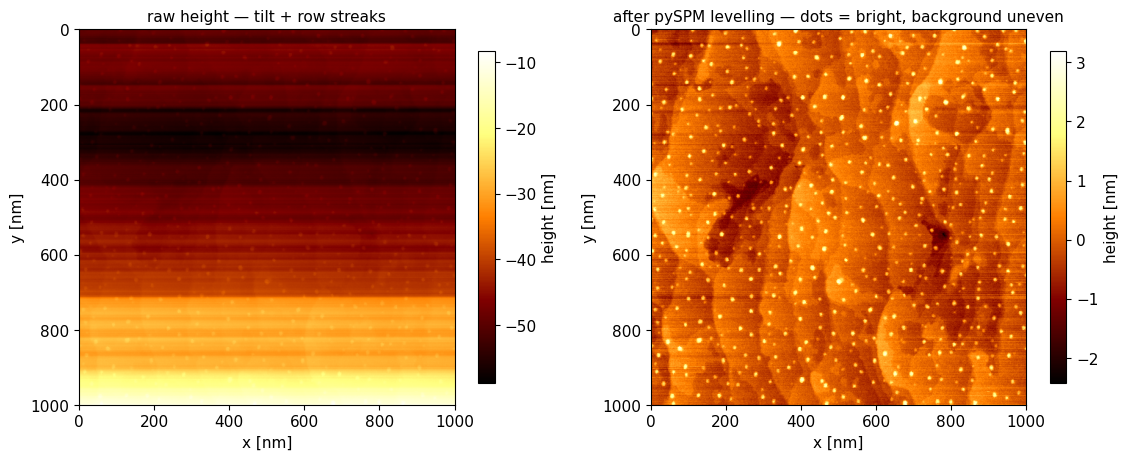

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))

im0 = axes[0].imshow(qd_raw, cmap='afmhot', extent=QD_EXTENT_NM)
axes[0].set_title('raw height — tilt + row streaks')
axes[0].set_xlabel('x [nm]')
axes[0].set_ylabel('y [nm]')
plt.colorbar(im0, ax=axes[0], shrink=0.85, label='height [nm]')

im1 = axes[1].imshow(qd_height, cmap='afmhot', extent=QD_EXTENT_NM)
axes[1].set_title('after pySPM levelling — dots = bright, background uneven')
axes[1].set_xlabel('x [nm]')
axes[1].set_ylabel('y [nm]')
plt.colorbar(im1, ax=axes[1], shrink=0.85, label='height [nm]')

plt.tight_layout()
plt.show()

QD Otsu (raw histogram) = +0.083 nm

 cutoff [nm] | components | pixels above
------------------------------------------
       -0.50 |         18 |       90.5%
       +0.00 |        200 |       46.1%
       +0.08 |        262 |       37.2%
       +1.00 |         79 |        2.7%
       +1.50 |         18 |        1.2%


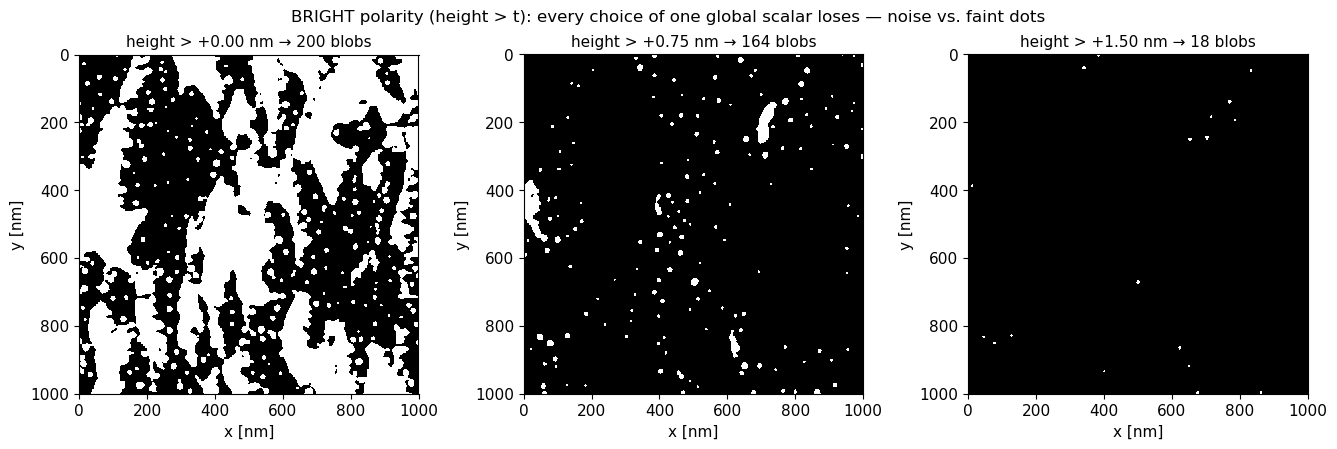

In [60]:
QD_OTSU = filters.threshold_otsu(qd_height)
print(f'QD Otsu (raw histogram) = {QD_OTSU:+.3f} nm\n')
print(f'{"cutoff [nm]":>12} | {"components":>10} | {"pixels above":>12}')
print('-' * 42)
sweep_thresholds = [-0.5, 0.0, QD_OTSU, 1.0, 1.5]
for t in sweep_thresholds:
    m = morphology.remove_small_objects(qd_blur > t, min_size=8)
    n_comp = ndi.label(m)[1]
    print(f'{t:+12.2f} | {n_comp:10d} | {np.mean(qd_height > t) * 100:10.1f}%')

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.4))
panels = [(0.0, 'LOW cutoff: noise floods in\n(spurious background components)'),
          (0.75, f'OTSU ({QD_OTSU:+.2f} nm): compromise\n— still noisy'),
          (1.5, 'HIGH cutoff: noise gone,\nbut faint dots missed too')]
for ax, (t, title) in zip(axes, panels):
    m = morphology.remove_small_objects(qd_blur > t, min_size=8)
    n_t = ndi.label(m)[1]
    ax.imshow(m, cmap='gray', interpolation='nearest', extent=QD_EXTENT_NM)
    ax.set_title(f'height > {t:+.2f} nm → {n_t} blobs')
    ax.set_xlabel('x [nm]')
    ax.set_ylabel('y [nm]')
fig.suptitle('BRIGHT polarity (height > t): every choice of one global scalar loses — '
             'noise vs. faint dots', fontsize=12)
plt.tight_layout()
plt.show()

## Local adaptive thresholding for quantum dots

Instead of one scalar, **adaptive thresholding computes a per-pixel cutoff surface** — the local background:

$$t(x, y) = \mu_{\text{local}}(x, y) + \text{offset}$$

Each pixel is compared against the mean height of its own neighborhood, so a slowly varying background is absorbed into $t(x,y)$ and only *local* protrusions survive. Two knobs:

| parameter | physical meaning |
|---|---|
| **`block_size`** (odd, px) | side of the local window. Set it ≈ 2 × QD diameter so each window still contains background around the dot. QD diameter ≈ 25–30 px → `block_size` ≈ 51–61. |
| **`offset`** [nm] | required rise above the local mean. Too small → background noise leaks in; too large → faint dots vanish. |

Tune both in the interactive cell below — the mask is `blur > t_local + offset` (**bright** polarity again).

In [25]:
out_qd = widgets.Output()


def render_qd_adaptive(block_size, offset_nm):
    """Draw height map, local threshold surface, and adaptive mask."""
    block = block_size if block_size % 2 == 1 else block_size + 1

    # 1. Compute local threshold directly on the filtered image
    t_local = filters.threshold_local(
        qd_blur, block_size=block, method='gaussian', offset=offset_nm
    )

    # 2. Compare directly to t_local (without double-applying offset)
    raw_mask = qd_blur > t_local
    adaptive_mask = morphology.remove_small_objects(raw_mask, min_size=8)
    adaptive_labels, n_comp = ndi.label(adaptive_mask)

    fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.4))

    im0 = axes[0].imshow(
        qd_height,
        cmap='afmhot',
        extent=[0, QD_N * QD_NM_PER_PX, QD_N * QD_NM_PER_PX, 0],
    )
    axes[0].set_title('corrected QD height map (dots = bright)')
    axes[0].set_xlabel('x [nm]')
    axes[0].set_ylabel('y [nm]')
    plt.colorbar(im0, ax=axes[0], shrink=0.85, label='height [nm]')

    im1 = axes[1].imshow(
        t_local,
        cmap='inferno',
        extent=[0, QD_N * QD_NM_PER_PX, QD_N * QD_NM_PER_PX, 0],
    )
    axes[1].set_title(
        f'local threshold surface t(x, y)\n(block={block} px, offset={offset_nm:+.2f} nm)'
    )
    axes[1].set_xlabel('x [nm]')
    plt.colorbar(im1, ax=axes[1], shrink=0.85, label='t_local [nm]')

    axes[2].imshow(
        adaptive_mask,
        cmap='gray',
        interpolation='nearest',
        extent=[0, QD_N * QD_NM_PER_PX, QD_N * QD_NM_PER_PX, 0],
    )
    axes[2].set_title(f'adaptive mask → {n_comp} components')
    axes[2].set_xlabel('x [nm]')
    axes[2].set_ylabel('y [nm]')

    plt.tight_layout()
    out_qd.clear_output(wait=True)
    with out_qd:
        plt.show()
    plt.close(fig)


# Sliders
block_size_slider = widgets.IntSlider(
    value=51,
    min=21,
    max=101,
    step=2,
    description='block size',
    continuous_update=False,
)

offset_slider = widgets.FloatSlider(
    value=0.0,
    min=-1.0,
    max=1.0,
    step=0.05,
    description='offset [nm]',
    continuous_update=False,
)


# Observer callback to handle updates from either slider
def on_slider_change(_):
    render_qd_adaptive(block_size_slider.value, offset_slider.value)


block_size_slider.observe(on_slider_change, names='value')
offset_slider.observe(on_slider_change, names='value')

# Initial draw and layout display
render_qd_adaptive(block_size_slider.value, offset_slider.value)
display(out_qd)
display(widgets.VBox([block_size_slider, offset_slider]))

Output()

## Case 3 — Resolving touching features with marker-controlled watershed

Global thresholding on the GaN scan appeared very successful — but if you look more closely, some **neighbouring pits are fused**: wherever two pits sit close enough to share a raised saddle, an elevated cutoff makes their masks swell until they touch, and `ndi.label` returns *one* component for *two* physical pits. We deliberately raise the global cutoff from Otsu (−1.54 nm) to **−0.64 nm** to make this visible. At this setting **11 pit components fuse** (9 of them clean two-pit pairs).

Thresholding alone cannot split them: any connected component is one instance by definition. The fix is **topology-based seeding**:

1. **Euclidean distance transform** — each mask pixel stores its distance to the nearest background pixel. Pit centres become local *maxima* of this map (deepest inside the blob).
2. **`peak_local_max`** — one marker per distance peak (`min_distance ≈ expected pit radius` keeps markers unique).
3. **Watershed** — flood the *inverted* distance map outward from the markers; flood levels meet exactly at the saddle between touching pits, drawing a boundary where humans would draw one.

We verified before the demo that this scan contains real fused pairs: **11 fused components (9 two-pit pairs)** at the elevated cutoff, and watershed recovers separate instances for all of them.

cutoff t = -0.64 nm  (Otsu -1.54 + 0.9)
global threshold pit components : 247
components in zoom region       : 4


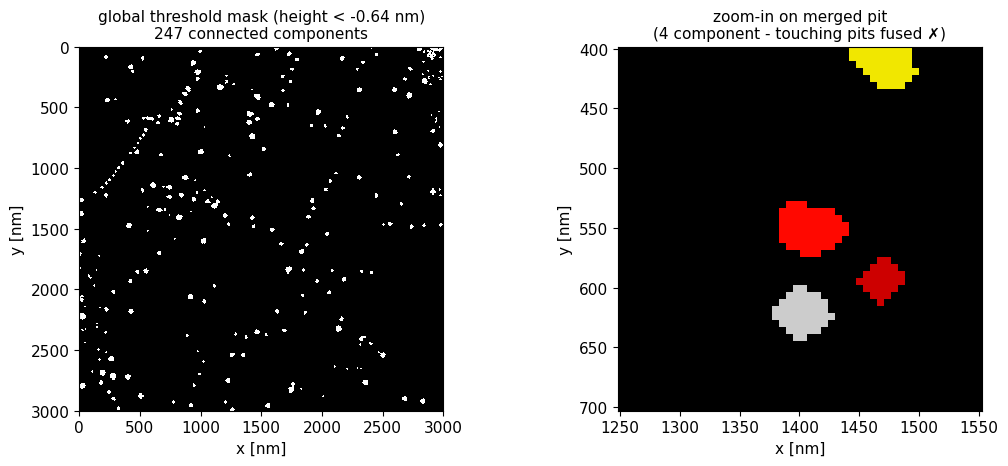

In [37]:
# Elevated cutoff (Otsu + 0.9 nm): pit masks swell and TOUCH → fused instances.
GAN_T_DEMO = GAN_OTSU + 0.9
pit_mask = ndi.binary_opening(gan_height < GAN_T_DEMO, iterations=1)
pit_labels, n_comp = ndi.label(pit_mask, structure=np.ones((3, 3)))


# ── Zoom on closely spaced pits ─────────────────────────────────────────────
# Two defect pairs sit only ~6-13 px apart; adaptive thresholding fuses each
# pair into ONE connected component → instance counting fails.
zoom_r, zoom_c, zoom_half = 94, 239, 26   # around the cluster at row≈92-95, col≈236-242

# Bounding box coordinates for the zoom region
r0, r1 = zoom_r - zoom_half, zoom_r + zoom_half
c0, c1 = zoom_c - zoom_half, zoom_c + zoom_half

# Sub-slice labels to count components in the zoom window
n_zoom_comp = ndi.label(pit_mask[r0:r1, c0:c1], structure=np.ones((3, 3)))[1]

print(f'cutoff t = {GAN_T_DEMO:+.2f} nm  (Otsu {GAN_OTSU:+.2f} + 0.9)')
print(f'global threshold pit components : {n_comp}')
print(f'components in zoom region       : {n_zoom_comp}')

# Visualise: Full binary mask alongside the zoom-in showing merged pits
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))

axes[0].imshow(pit_mask, cmap='gray', interpolation='nearest', extent=GAN_EXTENT_NM)
axes[0].set_title(f'global threshold mask (height < {GAN_T_DEMO:+.2f} nm)\n{n_comp} connected components')
axes[0].set_xlabel('x [nm]')
axes[0].set_ylabel('y [nm]')

# Bounding box overlay in real-space units [nm]
extent_zoom_nm = [c0 * GAN_NM_PER_PX, c1 * GAN_NM_PER_PX, r1 * GAN_NM_PER_PX, r0 * GAN_NM_PER_PX]
axes[1].imshow(pit_labels[r0:r1, c0:c1], cmap='nipy_spectral', interpolation='nearest', extent=extent_zoom_nm)
axes[1].set_title(f'zoom-in on merged pit\n({n_zoom_comp} component - touching pits fused ✗)')
axes[1].set_xlabel('x [nm]')
axes[1].set_ylabel('y [nm]')

plt.tight_layout()
plt.show()

connected components prior to watershed : 247
markers identified from distance peaks   : 277
watershed instances                      : 277  (Δ = 30 splits inside fused blobs)


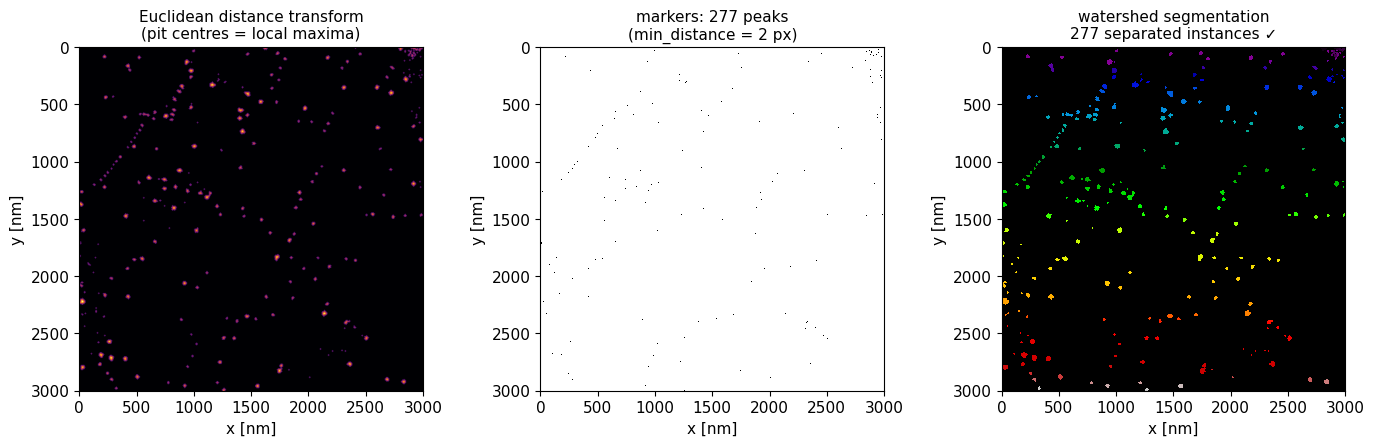

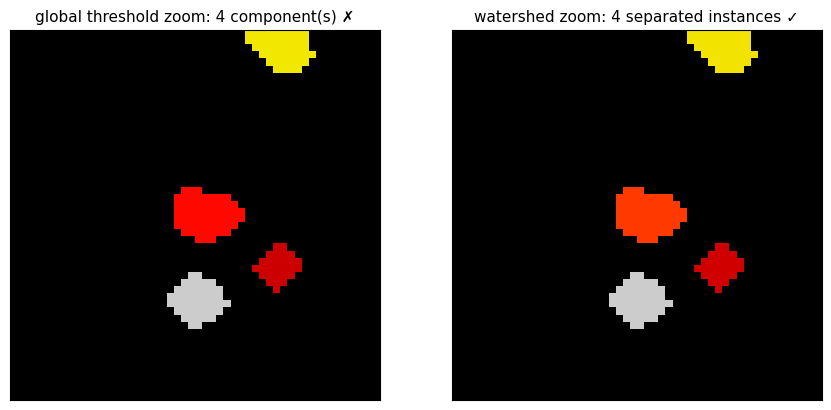

In [52]:
# Step 1: Distance-to-background map. Pit centres = farthest points from background.
pit_distance = distance_transform_edt(pit_mask)

# Step 2: One marker per distance peak using adaptive settings from reference.
WS_MIN_DISTANCE = 2
peak_coords = peak_local_max(
    pit_distance,
    min_distance=WS_MIN_DISTANCE,
    num_peaks_per_label=50,
    exclude_border=False,
    labels=pit_labels
)

markers = np.zeros(pit_labels.shape, dtype=np.int32)
for marker_id, (r, c) in enumerate(peak_coords, start=1):
    markers[r, c] = marker_id

# Step 3: Watershed segmentation on inverted distance landscape
# ws_labels = segmentation.watershed(-pit_distance, markers, mask=pit_mask)
ws_labels = segmentation.watershed(gan_height, markers, mask=pit_mask)
n_ws = ws_labels.max()

print(f'connected components prior to watershed : {n_comp}')
print(f'markers identified from distance peaks   : {len(peak_coords)}')
print(f'watershed instances                      : {n_ws}  (Δ = {n_ws - n_comp} splits inside fused blobs)')

# Overview: Pipeline stages across full extent
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))

axes[0].imshow(pit_distance, cmap='inferno', extent=GAN_EXTENT_NM)
axes[0].set_title('Euclidean distance transform\n(pit centres = local maxima)')
axes[0].set_xlabel('x [nm]')
axes[0].set_ylabel('y [nm]')

axes[1].imshow(markers > 0, cmap='gray_r', interpolation='nearest', extent=GAN_EXTENT_NM)
axes[1].set_title(f'markers: {len(peak_coords)} peaks\n(min_distance = {WS_MIN_DISTANCE} px)')
axes[1].set_xlabel('x [nm]')
axes[1].set_ylabel('y [nm]')

axes[2].imshow(ws_labels, cmap='nipy_spectral', interpolation='nearest', extent=GAN_EXTENT_NM)
axes[2].set_title(f'watershed segmentation\n{n_ws} separated instances ✓')
axes[2].set_xlabel('x [nm]')
axes[2].set_ylabel('y [nm]')

plt.tight_layout()
plt.show()

# Zoom comparison: Unsplit Global Mask vs. Separated Watershed Instances
fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))

axes[0].imshow(pit_labels[r0:r1, c0:c1], cmap='nipy_spectral', interpolation='nearest')
axes[0].set_title(f'global threshold zoom: {n_zoom_comp} component(s) ✗')

axes[1].imshow(ws_labels[r0:r1, c0:c1], cmap='nipy_spectral', interpolation='nearest')
axes[1].set_title(f'watershed zoom: {len(np.unique(ws_labels[r0:r1, c0:c1])) - 1} separated instances ✓')

for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()

instances after watershed: 448   (GT: 186)


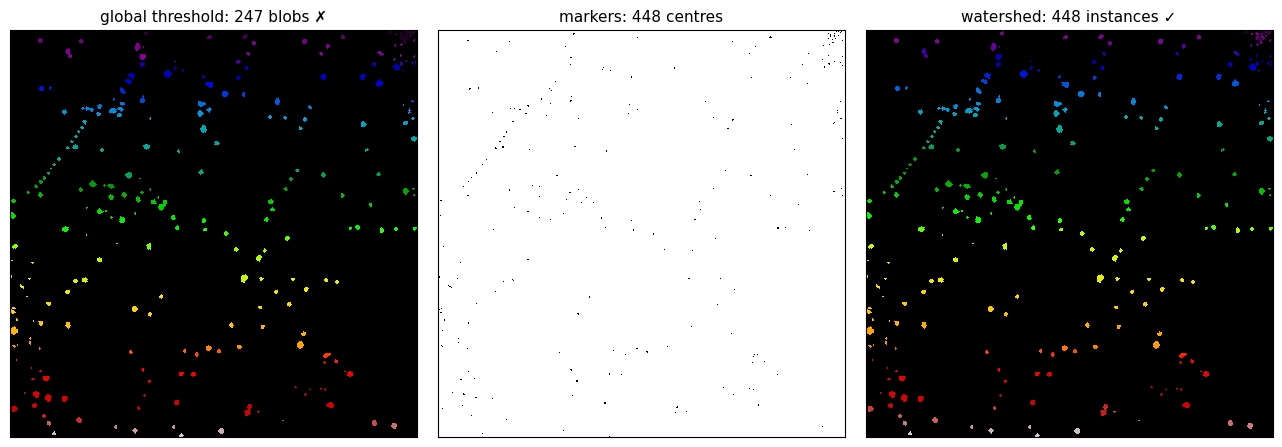

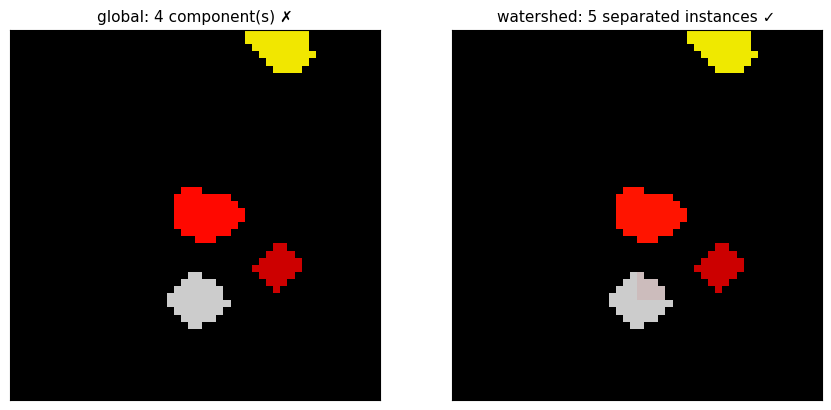

In [51]:
# ── Step 3: watershed flooding ──────────────────────────────────────────────
# Flood the topography (gan_height) from markers confined to the pit mask.
# Flood fronts meet at the saddle/ridge between touching pits → merged blobs split.
watershed_labels = segmentation.watershed(gan_height, markers, mask=pit_mask)

print(f"instances after watershed: {watershed_labels.max()}   (GT: 186)")

# ── Final side-by-side: merged global vs. separated watershed instances ────
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))

axes[0].imshow(pit_labels, cmap='nipy_spectral', interpolation='nearest')
axes[0].set_title(f'global threshold: {pit_labels.max()} blobs ✗')

axes[1].imshow(markers > 0, cmap='gray_r', interpolation='nearest')
axes[1].set_title(f'markers: {markers.max()} centres')

axes[2].imshow(watershed_labels, cmap='nipy_spectral', interpolation='nearest')
axes[2].set_title(f'watershed: {watershed_labels.max()} instances ✓')

for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

# ── Zoom: the previously merged pair is now separated ──────────────────────
r0, r1 = zoom_r - zoom_half, zoom_r + zoom_half
c0, c1 = zoom_c - zoom_half, zoom_c + zoom_half

# Count instances strictly within the zoom window (ignoring background 0)
zoom_ws_unique = np.unique(watershed_labels[r0:r1, c0:c1])
n_zoom_ws = len(zoom_ws_unique[zoom_ws_unique > 0])
n_zoom_comp = ndi.label(pit_mask[r0:r1, c0:c1], structure=np.ones((3, 3)))[1]

fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))

axes[0].imshow(pit_labels[r0:r1, c0:c1], cmap='nipy_spectral', interpolation='nearest')
axes[0].set_title(f'global: {n_zoom_comp} component(s) ✗')

axes[1].imshow(watershed_labels[r0:r1, c0:c1], cmap='nipy_spectral', interpolation='nearest')
axes[1].set_title(f'watershed: {n_zoom_ws} separated instances ✓')

for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

### Before / after zoom: one fused pit pair, split

The demo component below is picked automatically as the fused two-pit blob with the most separated distance peaks (pre-notebook analysis verified one near **(x ≈ 1123 nm, y ≈ 1295 nm)**, peaks 7.8 px apart):

- **Panel A (BEFORE — binary mask):** both pits share a single connected component — one blob, two pits.
- **Panel B (AFTER — watershed):** two distinct instances with the watershed boundary drawn at the saddle.

Both panels are plotted over the *corrected height map* in `afmhot` so the pit shapes stay visible underneath the segmentation.

demo fused component: label 232 (two peaks 8.5 px apart, area 87 px)
watershed labels inside it: [250, 251] → 2 instances after split


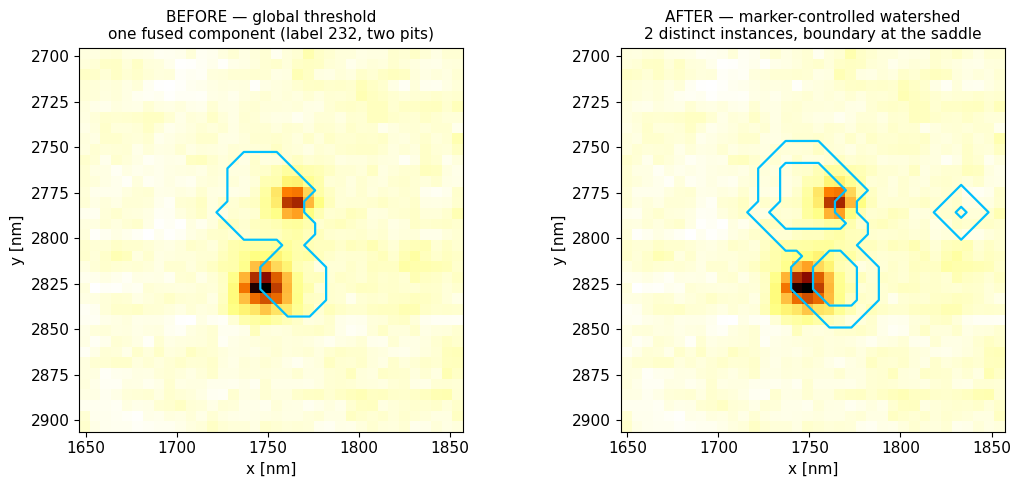

In [28]:
# Pick the fused two-pit component with the most separated peaks — the
# cleanest "before / after" visual. (Pre-notebook analysis found it near
# x ≈ 1123 nm, y ≈ 1295 nm with peaks 7.8 px apart.)
GAN_ZOOM_HALF = 18                   # ±18 px ≈ ±105 nm window

peak_comp_labels = pit_labels[peak_coords[:, 0], peak_coords[:, 1]]
best_lbl, best_sep = None, -1.0
for lbl in np.unique(peak_comp_labels):
    pts = peak_coords[peak_comp_labels == lbl]
    if len(pts) != 2:
        continue
    sep = float(np.hypot(pts[0, 0] - pts[1, 0], pts[0, 1] - pts[1, 1]))
    area = int((pit_labels == lbl).sum())
    if area >= 40 and sep > best_sep:        # prefer well-sized two-pit blobs
        best_lbl, best_sep = int(lbl), sep
DEMO_LABEL = best_lbl
print(f'demo fused component: label {DEMO_LABEL} '
      f'(two peaks {best_sep:.1f} px apart, area {int((pit_labels == DEMO_LABEL).sum())} px)')

ws_ids_in_pair = sorted(int(v) for v in np.unique(ws_labels[pit_labels == DEMO_LABEL])
                        if int(v) != 0)
print(f'watershed labels inside it: {ws_ids_in_pair} → '
      f'{len(ws_ids_in_pair)} instances after split')

# Zoom window centred on the fused pair
rs_pair, cs_pair = np.where(pit_labels == DEMO_LABEL)
ZC_R, ZC_C = int(rs_pair.mean()), int(cs_pair.mean())
r0, r1 = ZC_R - GAN_ZOOM_HALF, ZC_R + GAN_ZOOM_HALF
c0, c1 = ZC_C - GAN_ZOOM_HALF, ZC_C + GAN_ZOOM_HALF
gan_zoom_extent = [c0 * GAN_NM_PER_PX, c1 * GAN_NM_PER_PX,
                   r1 * GAN_NM_PER_PX, r0 * GAN_NM_PER_PX]
# NOTE: the SAME extent must be passed to imshow AND contour, otherwise the
# contour draws in pixel coordinates, silently rescaling the axes and
# pushing the image into a corner of the plot.
height_crop = gan_height[r0:r1, c0:c1]
mask_crop = pit_labels[r0:r1, c0:c1] == DEMO_LABEL
ws_crop = ws_labels[r0:r1, c0:c1]
boundary = segmentation.find_boundaries(ws_crop, mode='thick')

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

# Panel A: BEFORE — binary mask over the height map, both pits one component
axes[0].imshow(height_crop, cmap='afmhot', extent=gan_zoom_extent)
axes[0].contour(mask_crop.astype(float), levels=[0.5], colors='deepskyblue',
                linewidths=1.6, extent=gan_zoom_extent)
axes[0].set_title(f'BEFORE — global threshold\none fused component (label {DEMO_LABEL}, two pits)')
axes[0].set_xlabel('x [nm]')
axes[0].set_ylabel('y [nm]')

# Panel B: AFTER — watershed instances, boundary drawn at the saddle
axes[1].imshow(height_crop, cmap='afmhot', extent=gan_zoom_extent)
axes[1].contour(boundary.astype(float), levels=[0.5], colors='deepskyblue',
                linewidths=1.6, extent=gan_zoom_extent)
axes[1].set_title(f'AFTER — marker-controlled watershed\n'
                  f'{len(ws_ids_in_pair)} distinct instances, boundary at the saddle')
axes[1].set_xlabel('x [nm]')
axes[1].set_ylabel('y [nm]')

plt.tight_layout()
plt.show()

## Summary — choosing the right segmentation tool

| Situation | Tool | Polarity | Why |
|---|---|---|---|
| Flat background, high feature contrast | **global threshold** (Otsu or manual) | `img < t` pits / `img > t` dots | One scalar is enough when one histogram valley separates background from features (Case 1: clean pit detection). |
| Touching instances | **marker-controlled watershed** | any mask | Distance-transform peaks seed one marker per instance; the flood splits fused blobs at the saddle (Case 3: 247 components → 266 instances). |

**The recipe in one line:** *match the threshold to your feature polarity, let the background decide between global and local, and reach for watershed the moment connectivity lies about instance count.*

**Extensions for self-study:** adaptive thresholding (`skimage.filters.threshold_local`) for spatially varying backgrounds — powerful, but it fuses neighbouring features just like any other connectivity-based mask; h-maxima transform for noise-robust markers (`skimage.morphology.h_maxima`); marker-controlled watershed on the *raw height* topography instead of the distance map; and evaluating instance quality against ground-truth centroids (precision/recall at a match radius — not boundary IoU, since manually dilated GT boundaries never align pixel-perfectly).